## Implement SARSA and Q-learning for the CliffWorld
1 (20pts). Implement a CliffWorldEnv based on Example 6.6 on Page 132 of Suton. You may reuse the WindyWorldEnv class in the lecture note

In [39]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
class CliffWorldEnv(gym.Env):
    def __init__(self, start_state = (0,0), epsilon = 0.1,epsilon_decay = 1.0):
        super().__init__()
        self.agent_state = start_state
        self.action_space = [(-1,0),(1,0),(0,-1),(0,1)] #W, E, S, N
        self.goal_states = {(11,0)}
        self.states = [(i,j) for i in range(12) for j in range(4)]
        self.cliff = {(x,0)for x in range(1,11)}
        self.start_state = start_state
        self.xmax = 11; self.xmin = 0
        self.ymax = 3; self.ymin = 0
        self.q = {(s, a): 0.0 for s in self.states for a in self.action_space}
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
    
    def random_argmax(self, q):
        q = np.array(q)
        max_val = np.max(q)
        max_indices = np.where(q == max_val)[0]
        return np.random.choice(max_indices)

    def policy(self, s):# return [[a, p], ...] for ALL actions
        # greedy action: 1 - eps + eps/n, every other action: eps/n
        n = len(self.action_space)
        probs = [self.epsilon / n] * n
        best = self.random_argmax([self.q[(s, a)] for a in self.action_space])  # ties -> one action
        probs[best] += 1 - self.epsilon
        return [[a, p] for a, p in zip(self.action_space, probs)]
        
            
    def dynamics(self, s, a): #Needed to mock the envrion. this calculates P(s', r|s, a), it return [[s', r, p],...]  

        if s in self.goal_states:
            return []
        s2 = s[0] + a[0] , s[1] + a[1] 
        s2 = min(self.xmax, max(s2[0], self.xmin)), min(self.ymax, max(s2[1], self.ymin))
        if s2 in self.goal_states:
            return [[s2, 0, 1.0]]
        if s2 in self.cliff:
            return [[self.start_state,-100,1.0]]
        return [[s2, -1, 1.0]]
                
    def reset(self,seed=None, options=None): # return initial observation, info. Reset the start_state if options has "start_state"
        super().reset(seed=seed)
        options = options or {}
        if "start_state" in options:
            self.start_state = options["start_state"]
        self.agent_state = self.start_state
        return self.agent_state, {}
    
    def sample_action(self, s): # return a sampled action according to the policy in state s
        pi = self.policy(s)
        actions = [x[0] for x in pi]
        probs = [x[1] for x in pi]
        return random.choices(actions, weights=probs, k=1)[0]
        
    def sample_state_reward(self, s, a): # given action, find the next state and reward based on dynamics
        res = self.dynamics(s, a) # [[s', r, p],...]
        states_rewards = [srp[:2] for srp in res]
        probs = [srp[-1] for srp in res]
        return random.choices(states_rewards, weights=probs, k=1)[0]
        
    def step(self, a): # return observation, reward, terminated, truncated, info
        s = self.agent_state
        [s2, reward] = self.sample_state_reward(s, a) # sample s', r given s, a
        self.agent_state = s2
        done = self.agent_state in self.goal_states
        if done:                                     
            self.epsilon *= self.epsilon_decay 
        return self.agent_state, reward, done, False, {}
        
    def episode(self, start_state=None,max_steps=200):  # returns [(s, a, r, s'), ...] with Q fixed
        res = []
        options = {"start_state": start_state} if start_state is not None else None
        state, _ = self.reset(options=options)                  
        for _ in range(max_steps):                              
            action = self.sample_action(state)
            new_state, reward, terminated, truncated, info = self.step(action)
            res.append((state, action, reward, new_state))
            state = new_state
            if terminated:
                self.reset()
                return res
        self.reset()                                            
        return res 
               

2 (20pts). Implement SARSA, it should return the environment, and a stats object that contains `[[sum_reward, len_episode], ... ]` where the i-th element is the sum of rewards after i-episode

In [40]:
def SARSA(env:CliffWorldEnv, gamma = 1, alpha = 0.5, max_episode = 170, seed = 123, verbose = False):
    random.seed(seed)
    np.random.seed(seed)
    states = env.states
    terminal_states = env.goal_states
    steps = 0; stats = []
    
    for i in range(max_episode):
        delta = 0
        s, _ = env.reset()
        a = env.sample_action(s)
        len_episode = 0
        G = 0
        while True:
            len_episode += 1; steps += 1
            s2, r, terminated, truncated, info = env.step(a)
            G += r * gamma
            qold = env.q[s,a]
            if terminated:
                env.q[s, a] = qold + alpha * (r - qold)
                delta = max(delta, np.abs(env.q[s, a] - qold))
                break
            a2 = env.sample_action(s2)
            env.q[s, a] = qold + alpha*(r + gamma*env.q[s2, a2] - qold)
            delta = max(delta, np.abs(env.q[s, a] - qold))
            s, a = s2, a2
        stats = stats + [[steps, i,G]]
        if i%100 == 0:
            print(f' iter = {i}, delta = {delta}, episode_len = {len_episode}')
    return env, stats

3(15pts). Implement Q-learning, it should return the environment, and a stats object that contains `[[sum_reward, len_episode], ... ]` where the i-th element is the sum of rewards after i-episode

In [41]:
def Q_Learning(env, gamma = 1, alpha = 0.5, max_episode = 170, seed = 123, verbose = False):
 
    np.random.seed(seed)
    random.seed(seed)
    states = env.states
    terminal_states = env.goal_states
    steps = 0; stats = []
    
    for i in range(max_episode):
        delta = 0
        s, _ = env.reset()
        len_episode = 0
        G = 0
        while True:
            a = env.sample_action(s)
            len_episode += 1; steps += 1
            s2, r, terminated, truncated, info = env.step(a) 
            G += r * gamma
            qold = env.q[s,a]
            if terminated:
                env.q[s, a] = qold + alpha * (r - qold)
                delta = max(delta, abs(env.q[s, a] - qold))  
                env.reset()
                break
            qmax = max(env.q[s2, a2] for a2 in env.action_space)
            env.q[s, a] = qold + alpha*(r + gamma*qmax - qold)
            delta = max(delta, np.abs(env.q[s, a] - qold))
            s = s2
        stats = stats + [[steps, i,G]]
        if i%100 == 0:
            print(f' iter = {i}, delta = {delta}, episode_len = {len_episode}')
    return env, stats

4 (15pts). Plot sum of reward vs episode. To reduce noise, we average the sum of rewards over 50 runs

In [42]:
runs = 50
stats_sarsa = []
for run in range(runs):
    env = CliffWorldEnv(epsilon = 0.1)
    env, stat = SARSA(env, max_episode = 500, alpha = 0.1, seed = run)
    stats_sarsa.append(stat)

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 8.56958243102968, episode_len = 64
 iter = 200, delta = 0.12850527274303225, episode_len = 25
 iter = 300, delta = 0.257192619012125, episode_len = 19
 iter = 400, delta = 0.19387898298441186, episode_len = 21
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.31586022912155, episode_len = 39
 iter = 200, delta = 0.17845082478046415, episode_len = 19
 iter = 300, delta = 0.030082782258756602, episode_len = 15
 iter = 400, delta = 0.015026938283413394, episode_len = 15
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 5.497245063603302, episode_len = 33
 iter = 200, delta = 0.18460371001159892, episode_len = 21
 iter = 300, delta = 0.16569893034378147, episode_len = 19
 iter = 400, delta = 0.16063145179280802, episode_len = 20
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.2866631891061244, episode_len = 43
 iter = 200, 

In [43]:
stats_Q = []
for run in range(runs):
    env = CliffWorldEnv(epsilon = 0.1)
    env, stat = Q_Learning(env, max_episode = 500, alpha = 0.1, seed = run)
    stats_Q.append(stat)

 iter = 0, delta = 10.11, episode_len = 502
 iter = 100, delta = 0.15496136721363296, episode_len = 19
 iter = 200, delta = 0.18518150189006555, episode_len = 17
 iter = 300, delta = 0.08221636555389367, episode_len = 15
 iter = 400, delta = 2.427456387010807e-07, episode_len = 13
 iter = 0, delta = 10.139902121, episode_len = 676
 iter = 100, delta = 0.12177999180549692, episode_len = 23
 iter = 200, delta = 6.133570487131294, episode_len = 42
 iter = 300, delta = 0.0992603232144873, episode_len = 15
 iter = 400, delta = 0.015009463529699896, episode_len = 14
 iter = 0, delta = 10.090000000000002, episode_len = 316
 iter = 100, delta = 0.1681566010322988, episode_len = 29
 iter = 200, delta = 4.135377704701355, episode_len = 22
 iter = 300, delta = 0.08880475482479433, episode_len = 15
 iter = 400, delta = 0.1079881464540593, episode_len = 17
 iter = 0, delta = 10.146652339165716, episode_len = 779
 iter = 100, delta = 0.1488630246900433, episode_len = 23
 iter = 200, delta = 0.115399

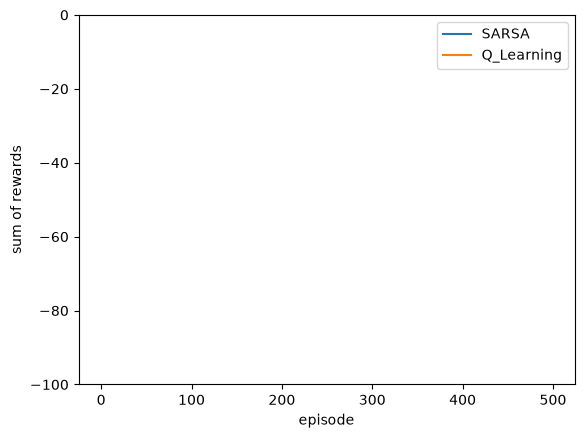

In [44]:
plt.plot(np.array(stats_sarsa)[:,:,0].mean(axis = 0), label = 'SARSA')
plt.plot(np.array(stats_Q)[:,:,0].mean(axis = 0), label = 'Q_Learning')
plt.ylim(-100,0)
plt.xlabel('episode')
plt.ylabel('sum of rewards')
plt.legend(); 

5 (15pts). Plot 10 episodes, and discuss the difference you observe between the trajectory of SARSA vs Q

In [45]:
import matplotlib.pyplot as plt
import numpy as np

def to_xy(s, height=4):                                   
    x, y = s                                        
    return x + 0.5, y + 0.5   

def plot_episodes(episodes, title = "alg"):
    width, height = 12, 4

    fig, ax = plt.subplots(figsize=(10,3))

    # draw grid
    for x in range(width+1):
        ax.plot([x,x],[0,height],color='black',linewidth=0.5)
    for y in range(height+1):
        ax.plot([0,width],[y,y],color='black',linewidth=0.5)

    # draw cliff
    for x in range(1,11):
        ax.add_patch(plt.Rectangle((x,0),1,1,color='red',alpha=0.3))

    # start and goal
    ax.text(0.5,0.5,"S",ha='center',va='center',fontsize=14)
    ax.text(11.5,0.5,"G",ha='center',va='center',fontsize=14)

    colors = plt.cm.tab10(np.linspace(0,1,len(episodes)))

    for i,episode in enumerate(episodes):

        xs = []
        ys = []

        # small jitter so paths don't perfectly overlap
        jitter = (i - len(episodes)/2) * 0.03

        for (s,a,r,s2) in episode:
            x,y = to_xy(s,height)
            xs.append(x + jitter)
            ys.append(y + jitter)

        # add final state
        x, y = to_xy(episode[-1][3], height)
        xs.append(x + jitter)
        ys.append(y + jitter)

        ax.plot(xs, ys, '-o', color=colors[i], label=f'Episode {i+1}', linewidth=2, markersize=3)

    ax.set_xlim(0,width)
    ax.set_ylim(0,height)
    ax.set_aspect('equal')

    ax.set_xticks(range(width+1))
    ax.set_yticks(range(height+1))

    ax.legend(loc='upper center', ncol=5, bbox_to_anchor=(0.5,1.15))

    ax.set_title("Cliff Walking Episodes: " + title)

    plt.show()


 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 8.56958243102968, episode_len = 64
 iter = 200, delta = 0.12850527274303225, episode_len = 25
 iter = 300, delta = 0.257192619012125, episode_len = 19
 iter = 400, delta = 0.19387898298441186, episode_len = 21
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.31586022912155, episode_len = 39
 iter = 200, delta = 0.17845082478046415, episode_len = 19
 iter = 300, delta = 0.030082782258756602, episode_len = 15
 iter = 400, delta = 0.015026938283413394, episode_len = 15
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 5.497245063603302, episode_len = 33
 iter = 200, delta = 0.18460371001159892, episode_len = 21
 iter = 300, delta = 0.16569893034378147, episode_len = 19
 iter = 400, delta = 0.16063145179280802, episode_len = 20
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.2866631891061244, episode_len = 43
 iter = 200, 

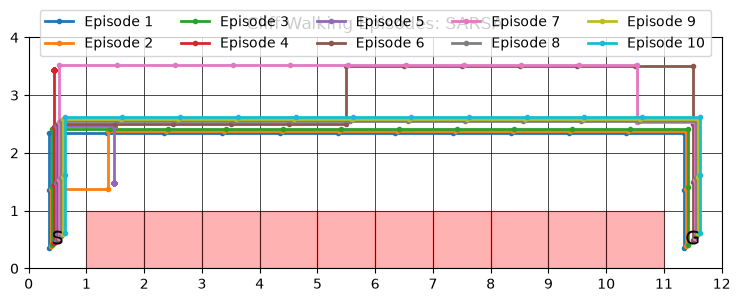

In [46]:
episodes = []
for run in range(10):
    env = CliffWorldEnv(epsilon = 0.1)
    env, stat = SARSA(env, max_episode = 500, alpha = 0.1, seed = run)
    env.epsilon = 0
    episodes.append(env.episode())
plot_episodes(episodes, title = 'SARSA')

 iter = 0, delta = 10.11, episode_len = 502
 iter = 100, delta = 0.15496136721363296, episode_len = 19
 iter = 200, delta = 0.18518150189006555, episode_len = 17
 iter = 300, delta = 0.08221636555389367, episode_len = 15
 iter = 400, delta = 2.427456387010807e-07, episode_len = 13
 iter = 0, delta = 10.139902121, episode_len = 676
 iter = 100, delta = 0.12177999180549692, episode_len = 23
 iter = 200, delta = 6.133570487131294, episode_len = 42
 iter = 300, delta = 0.0992603232144873, episode_len = 15
 iter = 400, delta = 0.015009463529699896, episode_len = 14
 iter = 0, delta = 10.090000000000002, episode_len = 316
 iter = 100, delta = 0.1681566010322988, episode_len = 29
 iter = 200, delta = 4.135377704701355, episode_len = 22
 iter = 300, delta = 0.08880475482479433, episode_len = 15
 iter = 400, delta = 0.1079881464540593, episode_len = 17
 iter = 0, delta = 10.146652339165716, episode_len = 779
 iter = 100, delta = 0.1488630246900433, episode_len = 23
 iter = 200, delta = 0.115399

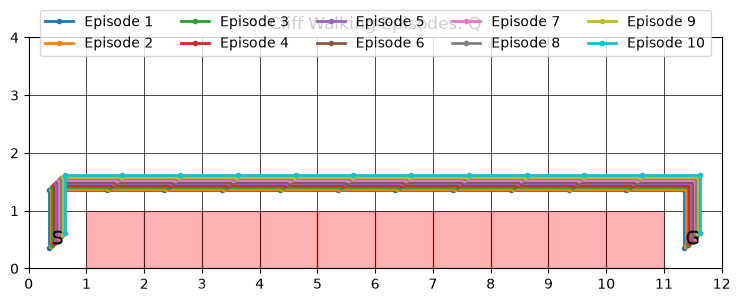

In [47]:
episodes = []
for run in range(10):
    env = CliffWorldEnv(epsilon = 0.1)
    env, stat = Q_Learning(env, max_episode = 500, alpha = 0.1, seed = run)
    env.epsilon = 0
    episodes.append(env.episode())
plot_episodes(episodes, title = 'Q')

6 (15 pts). Now introduce an `epsilon_decay` variable in `CliffWorldEnv`:

```python
def __init__(self, start_state=(0, 0), epsilon=0.1, epsilon_decay=1.0):
```

When `epsilon_decay = 1.0`, we use a constant $\epsilon$-greedy policy. Otherwise, update $\epsilon \leftarrow \text{epsilon\_decay} \cdot \epsilon$ every time the agent reaches a terminal state in the `step` function.

Run SARSA with different values of `epsilon_decay`, including values close to 1 and close to 0, and check whether SARSA's policy improves. Write down your observations.

episodes = []
epsilon_decay = #insert value
for run in range(10):
    env = CliffWorldEnv(epsilon = 0.1, epsilon_decay = epsilon_decay)
    env, stat = SARSA(env, max_episode = 500, alpha = 0.1, seed = run)
    env.epsilon = 0
    episodes.append(env.episode())
plot_episodes(episodes, title = 'SARSA')

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 8.56958243102968, episode_len = 64
 iter = 200, delta = 0.12850527274303225, episode_len = 25
 iter = 300, delta = 0.257192619012125, episode_len = 19
 iter = 400, delta = 0.19387898298441186, episode_len = 21
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.31586022912155, episode_len = 39
 iter = 200, delta = 0.17845082478046415, episode_len = 19
 iter = 300, delta = 0.030082782258756602, episode_len = 15
 iter = 400, delta = 0.015026938283413394, episode_len = 15
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 5.497245063603302, episode_len = 33
 iter = 200, delta = 0.18460371001159892, episode_len = 21
 iter = 300, delta = 0.16569893034378147, episode_len = 19
 iter = 400, delta = 0.16063145179280802, episode_len = 20
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.2866631891061244, episode_len = 43
 iter = 200, 

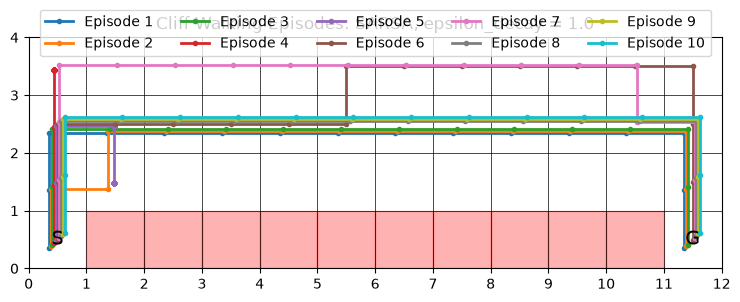

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 7.1442553066282315, episode_len = 62
 iter = 200, delta = 0.12126660515746757, episode_len = 17
 iter = 300, delta = 0.051903193277910376, episode_len = 15
 iter = 400, delta = 0.1709212286366597, episode_len = 17
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.17539213513069285, episode_len = 31
 iter = 200, delta = 0.4527946192594783, episode_len = 27
 iter = 300, delta = 0.09999999999999964, episode_len = 17
 iter = 400, delta = 0.09999999999999964, episode_len = 19
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 0.3204718639267812, episode_len = 27
 iter = 200, delta = 0.12038928261318915, episode_len = 19
 iter = 300, delta = 0.09999999999999964, episode_len = 19
 iter = 400, delta = 0.4558682880211542, episode_len = 16
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 6.117157060684242, episode_len = 32
 iter = 20

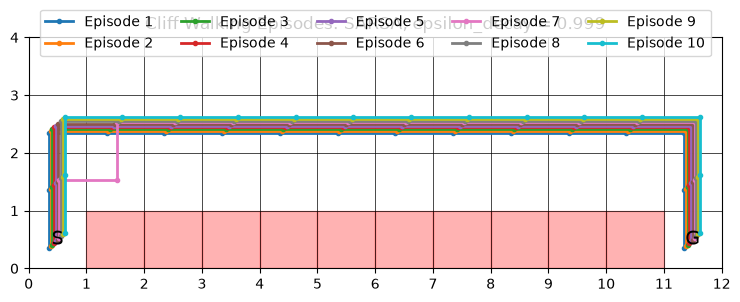

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 0.17638268666828694, episode_len = 48
 iter = 200, delta = 0.1828244800151424, episode_len = 19
 iter = 300, delta = 0.00787402222249689, episode_len = 15
 iter = 400, delta = 5.208678098256314e-05, episode_len = 15
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.15205027237053237, episode_len = 28
 iter = 200, delta = 0.1481273524697242, episode_len = 23
 iter = 300, delta = 0.09999999999999964, episode_len = 17
 iter = 400, delta = 0.0007002098810513502, episode_len = 15
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 0.16635870105268058, episode_len = 37
 iter = 200, delta = 0.06515614390217372, episode_len = 17
 iter = 300, delta = 0.13821016879887438, episode_len = 21
 iter = 400, delta = 0.033780209420259055, episode_len = 15
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.14140327066635994, episode_len = 19
 

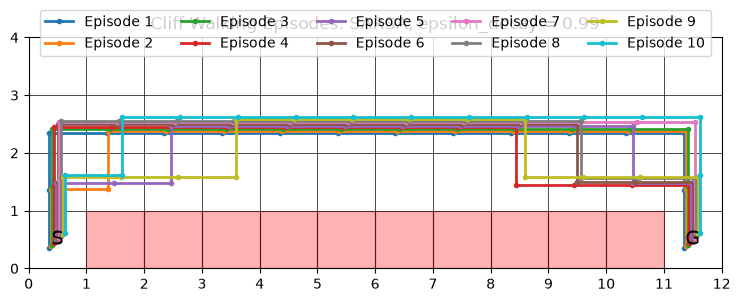

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 0.10578327469695203, episode_len = 19
 iter = 200, delta = 0.1810600647901932, episode_len = 23
 iter = 300, delta = 0.0030803667761034603, episode_len = 13
 iter = 400, delta = 8.775187062326495e-06, episode_len = 13
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.15612065655633156, episode_len = 41
 iter = 200, delta = 0.1837488032933905, episode_len = 19
 iter = 300, delta = 0.004567949468395227, episode_len = 13
 iter = 400, delta = 1.8601930225514707e-05, episode_len = 13
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 0.15084032991636498, episode_len = 35
 iter = 200, delta = 0.18386827051026167, episode_len = 17
 iter = 300, delta = 0.0016312286662483189, episode_len = 13
 iter = 400, delta = 1.5130854100320335e-05, episode_len = 13
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.13100988119239343, episode_le

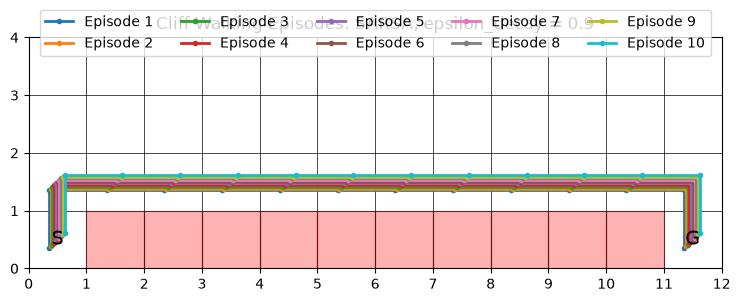

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 0.15446641653150106, episode_len = 31
 iter = 200, delta = 0.11913017375326085, episode_len = 17
 iter = 300, delta = 0.004292002294125297, episode_len = 13
 iter = 400, delta = 1.7399303125387178e-05, episode_len = 13
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.1455892645865351, episode_len = 21
 iter = 200, delta = 0.17999717319518105, episode_len = 25
 iter = 300, delta = 0.004067826824915244, episode_len = 13
 iter = 400, delta = 1.8717600415385505e-05, episode_len = 13
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 0.1525979076210815, episode_len = 31
 iter = 200, delta = 0.08261042806970398, episode_len = 15
 iter = 300, delta = 0.003831525934854696, episode_len = 13
 iter = 400, delta = 1.7693607412994083e-05, episode_len = 13
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.16084455707809386, episode_len

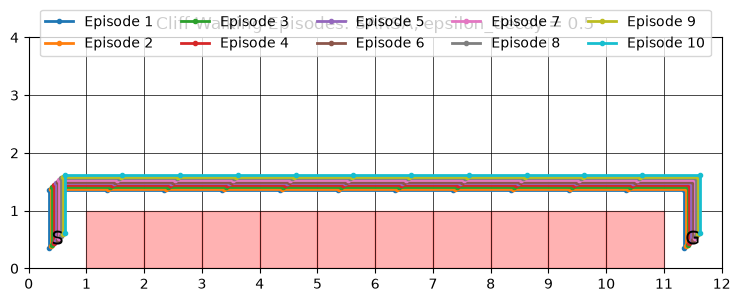

 iter = 0, delta = 10.115510204561856, episode_len = 536
 iter = 100, delta = 0.17151769788076887, episode_len = 53
 iter = 200, delta = 0.17092978761328048, episode_len = 17
 iter = 300, delta = 0.1473671532914942, episode_len = 21
 iter = 400, delta = 1.714192639212797e-05, episode_len = 13
 iter = 0, delta = 11.911974974754001, episode_len = 1013
 iter = 100, delta = 0.16349545833723367, episode_len = 33
 iter = 200, delta = 0.1758850321423977, episode_len = 25
 iter = 300, delta = 0.17273303845352306, episode_len = 21
 iter = 400, delta = 1.7937507244880635e-05, episode_len = 13
 iter = 0, delta = 10.163913349646423, episode_len = 685
 iter = 100, delta = 0.16102799931731004, episode_len = 31
 iter = 200, delta = 0.189580411736344, episode_len = 15
 iter = 300, delta = 0.003951037419897219, episode_len = 13
 iter = 400, delta = 1.671834652228199e-05, episode_len = 13
 iter = 0, delta = 10.135970000310056, episode_len = 606
 iter = 100, delta = 0.173953321119785, episode_len = 23
 i

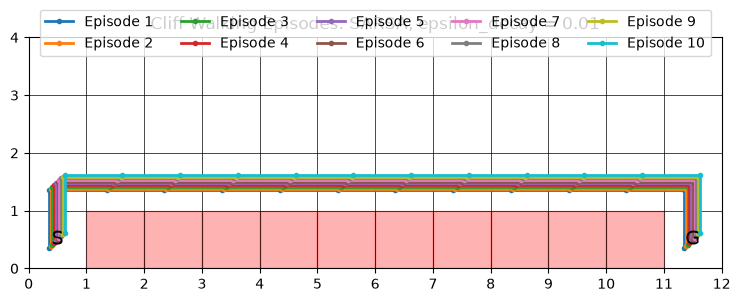

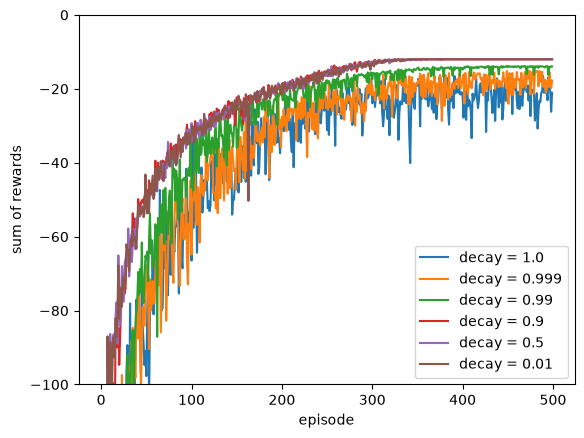

In [48]:
decays = [1.0, 0.999, 0.99, 0.9, 0.5, 0.01]
returns = {}
for epsilon_decay in decays:
    stats = []
    episodes = []
    for run in range(50):
        env = CliffWorldEnv(epsilon = 0.1, epsilon_decay = epsilon_decay)
        env, stat = SARSA(env, max_episode = 500, alpha = 0.1, seed = run)
        stats.append(stat)
        if run < 10:                          # greedy trajectory for the first 10 runs
            env.epsilon = 0
            episodes.append(env.episode())
    returns[epsilon_decay] = np.array(stats)[:,:,2].mean(axis = 0)
    plot_episodes(episodes, title = f'SARSA, epsilon_decay = {epsilon_decay}')

for epsilon_decay in decays:
    plt.plot(returns[epsilon_decay], label = f'decay = {epsilon_decay}')
plt.ylim(-100,0)
plt.xlabel('episode')
plt.ylabel('sum of rewards')
plt.legend();

# Observation: 

The higher `epsilon_decay` is, the further SARSA's path stays from the cliff, because SARSA learns the value of its own ε-greedy policy, including the risk of randomly stepping off the edge. When ε decays quickly (`epsilon_decay` ≤ 0.9), SARSA converges to the optimal edge path, and its return improves from about −22 to −12.

In [52]:
! python -m jupyter nbconvert 08_Model_Free_Control_hw-2.ipynb --to webpdf

[NbConvertApp] Converting notebook 08_Model_Free_Control_hw-2.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 10 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 542085 bytes to 08_Model_Free_Control_hw-2.pdf
